# FX Options: Market Conventions and the Vanna-Volga Smile

FX options trade in a language of their own. A salesperson does not quote "a 1.10 strike
call at 8.2% vol" but "**6-month 25-delta risk reversal at −0.60**". Strikes are expressed in
delta, the smile is described by three numbers, and the delta itself has several definitions.
This notebook goes from those quotes to a full smile and a price:

1. Garman-Kohlhagen pricing and the forward from covered interest parity
2. Delta conventions: spot, forward, premium-adjusted
3. From the three market quotes (ATM, 25Δ RR, 25Δ BF) to strikes and vols
4. The **vanna-volga** smile and pricing of any strike

Market data are illustrative of EUR/USD (spot 1.0850, USD rate 4.0%, EUR rate 2.5%).

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("fxopt.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/28-fx-options-vanna-volga")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fxopt import (forward, gk_price, delta, strike_from_delta, atm_dns_strike, pillar_vols, vanna_volga_vol,
                   vanna_volga_price, implied_vol)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
S, rd, rf = 1.0850, 0.040, 0.025

## 1. Forwards and Garman-Kohlhagen

Holding euros earns the euro rate $r_f$, so a currency behaves like a stock with a dividend
yield equal to the foreign rate: $F = S\,e^{(r_d - r_f)T}$ and
$C = e^{-r_dT}\,[F N(d_1) - K N(d_2)]$. Forward points are $F - S$, quoted in pips.

In [2]:
tenors = {"1M": 1 / 12, "3M": 0.25, "6M": 0.5, "1Y": 1.0, "2Y": 2.0}
pd.DataFrame({t: {"Forward": forward(S, T, rd, rf), "Forward points (pips)": (forward(S, T, rd, rf) - S) * 1e4}
              for t, T in tenors.items()}).T.round(4)

,Forward,Forward points (pips)
1M,1.0864,13.5710
3M,1.0891,40.7639
6M,1.0932,81.6809
1Y,1.1014,163.9768
2Y,1.1180,330.4317


## 2. Which delta?

| Convention | Formula (call) | Used when |
|---|---|---|
| Spot delta | $e^{-r_fT}N(d_1)$ | short tenors, most pairs |
| Forward delta | $N(d_1)$ | long tenors |
| Premium-adjusted | spot delta − premium / spot | the premium is paid in the foreign currency (USD/JPY, EM pairs) |

For the same option the numbers differ, so the same "25-delta" quote can mean different strikes.

In [3]:
T, vol = 0.5, 0.08
rows = []
for kind, pa in [("spot", False), ("forward", False), ("spot", True)]:
    Kc = strike_from_delta(0.25, S, T, rd, rf, vol, True, kind, pa)
    Kp = strike_from_delta(-0.25, S, T, rd, rf, vol, False, kind, pa)
    rows.append({"Convention": f"{kind}{' premium-adjusted' if pa else ''}", "25-delta call strike": Kc, "25-delta put strike": Kp})
rows.append({"Convention": "ATM delta-neutral straddle", "25-delta call strike": atm_dns_strike(S, T, rd, rf, vol),
             "25-delta put strike": atm_dns_strike(S, T, rd, rf, vol)})
pd.DataFrame(rows).set_index("Convention").round(5)

,25-delta call strike,25-delta put strike
Convention,,
spot,1.13687,1.05452
forward,1.13750,1.05393
spot premium-adjusted,1.13513,1.05293
ATM delta-neutral straddle,1.09492,1.09492


## 3. From market quotes to the smile pillars

A typical 6-month EUR/USD quote: **ATM 8.00%, 25Δ RR −0.60%, 25Δ BF +0.25%**.

- The **risk reversal** (25Δ call vol − 25Δ put vol) measures the skew: negative means euro
  puts are more expensive, i.e. the market pays more to protect against a euro fall.
- The **butterfly** (average of the wings − ATM) measures the curvature (fat tails).

With the smile-strangle convention: $\sigma_{25C} = ATM + BF + RR/2$ and $\sigma_{25P} = ATM + BF - RR/2$.
Each pillar vol is then turned into a strike with its own delta.

In [4]:
quotes = {"ATM": 0.080, "RR25": -0.006, "BF25": 0.0025}
pv = pillar_vols(quotes["ATM"], quotes["RR25"], quotes["BF25"])
K25P = strike_from_delta(-0.25, S, T, rd, rf, pv["25P"], call=False)
KATM = atm_dns_strike(S, T, rd, rf, pv["ATM"])
K25C = strike_from_delta(0.25, S, T, rd, rf, pv["25C"], call=True)
pillars_K, pillars_v = [K25P, KATM, K25C], [pv["25P"], pv["ATM"], pv["25C"]]
pd.DataFrame({"Strike": pillars_K, "Vol": pillars_v}, index=["25Δ put", "ATM DNS", "25Δ call"]).round(5)

,Strike,Vol
25Δ put,1.05203,0.0855
ATM DNS,1.09492,0.0800
25Δ call,1.13658,0.0795


## 4. Vanna-volga: the whole smile from three points

The idea is a hedging argument. Price any option with the ATM vol, then add the cost of
hedging its **vega**, **vanna** (vega sensitivity to spot) and **volga** (vega sensitivity to
vol) with the three liquid options at their market prices:

$$C_{VV}(K) = C_{BS}(K, \sigma_{ATM}) + \sum_{i=1}^{3} x_i(K)\,\big[C^{mkt}_i - C_{BS}(K_i, \sigma_{ATM})\big]$$

The weights $x_i$ make the three options match the target's vega, vanna and volga. The method
reproduces the three quotes exactly and interpolates or extrapolates the rest.

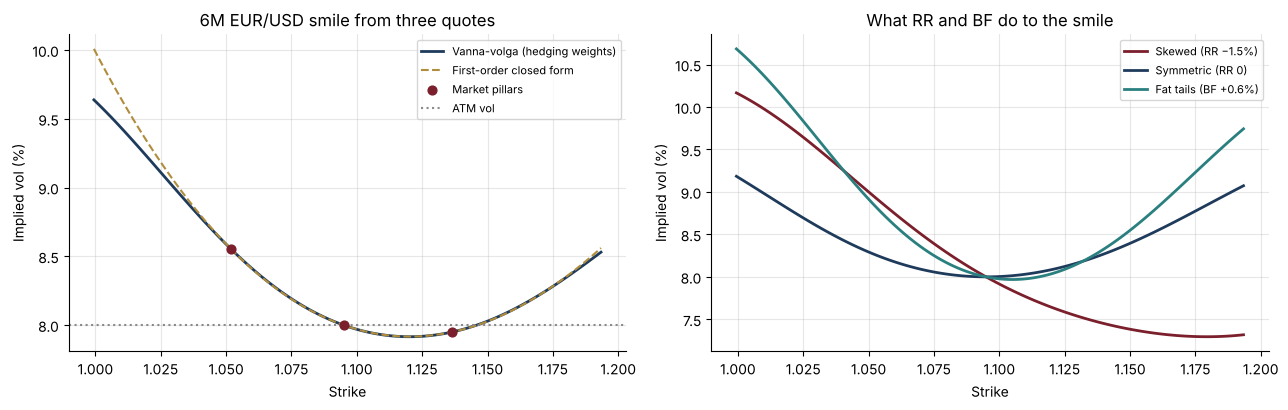

In [5]:
strikes = np.linspace(K25P * 0.95, K25C * 1.05, 120)
vv_closed = [vanna_volga_vol(K, pillars_K, pillars_v) for K in strikes]
vv_price = [implied_vol(vanna_volga_price(S, K, T, rd, rf, pillars_K, pillars_v), S, K, T, rd, rf) for K in strikes]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(strikes, np.array(vv_price) * 100, color=NAVY, lw=2, label="Vanna-volga (hedging weights)")
axes[0].plot(strikes, np.array(vv_closed) * 100, color=GOLD, lw=1.5, ls="--", label="First-order closed form")
axes[0].scatter(pillars_K, np.array(pillars_v) * 100, color=BORDEAUX, zorder=4, s=40, label="Market pillars")
axes[0].axhline(quotes["ATM"] * 100, color=GREY, ls=":", label="ATM vol")
axes[0].set(xlabel="Strike", ylabel="Implied vol (%)", title="6M EUR/USD smile from three quotes"); axes[0].legend(fontsize=8)
for (name, rr, bf), c in zip([("Skewed (RR −1.5%)", -0.015, 0.0025), ("Symmetric (RR 0)", 0.0, 0.0025), ("Fat tails (BF +0.6%)", -0.006, 0.006)],
                             [BORDEAUX, NAVY, TEAL]):
    p2 = pillar_vols(0.08, rr, bf)
    Ks = [strike_from_delta(-0.25, S, T, rd, rf, p2["25P"], False), atm_dns_strike(S, T, rd, rf, 0.08),
          strike_from_delta(0.25, S, T, rd, rf, p2["25C"], True)]
    axes[1].plot(strikes, [implied_vol(vanna_volga_price(S, K, T, rd, rf, Ks, [p2["25P"], 0.08, p2["25C"]]), S, K, T, rd, rf) * 100
                           for K in strikes], color=c, lw=2, label=name)
axes[1].set(xlabel="Strike", ylabel="Implied vol (%)", title="What RR and BF do to the smile"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/vv_smile.png", dpi=150); plt.show()

## 5. Pricing a client request

A corporate client wants to buy a 6-month EUR put / USD call struck at 1.0500 on EUR 10m, to
protect euro revenues. Pricing it at the ATM vol would ignore the skew.

In [6]:
K, notional = 1.0500, 10_000_000
vol_vv = implied_vol(vanna_volga_price(S, K, T, rd, rf, pillars_K, pillars_v, call=False), S, K, T, rd, rf, call=False)
p_atm = gk_price(S, K, T, rd, rf, quotes["ATM"], call=False)
p_vv = vanna_volga_price(S, K, T, rd, rf, pillars_K, pillars_v, call=False)
pd.Series({"Strike": K, "Delta (spot, % of notional)": delta(S, K, T, rd, rf, vol_vv, call=False) * 100,
           "Vol at ATM": quotes["ATM"], "Vanna-volga vol": vol_vv,
           "Premium at ATM vol (USD)": p_atm * notional, "Premium with the smile (USD)": p_vv * notional,
           "Smile cost (USD)": (p_vv - p_atm) * notional, "Premium in % of EUR notional": p_vv / S * 100}).round(4).to_frame("Quote")

,Quote
Strike,1.0500
"Delta (spot, % of notional)",-24.0869
Vol at ATM,0.0800
Vanna-volga vol,0.0859
Premium at ATM vol (USD),83115.2936
Premium with the smile (USD),96867.6960
Smile cost (USD),13752.4024
Premium in % of EUR notional,0.8928


## Conclusions
- FX quotes live in delta space; the convention (spot, forward, premium-adjusted) changes the
  strike, and getting it wrong misprices the trade.
- Vanna-volga turns three liquid quotes into a full smile, reproduces them exactly (tested) and
  gives a price consistent with how traders hedge.
- The skew is not a detail: on this client put, it adds about USD 14k (17%) to the premium.
- **Next steps:** a full volatility surface across tenors, SABR calibration as an alternative,
  barrier and touch options priced with vanna-volga, and the broker-fly vs smile-fly distinction.